# ABox-to-TBox Ontology Induction Pipeline (v2.3)

A step-by-step, procedural ontology induction pipeline: **ABox.ttl in, TBox.ttl out**.

* **Zero `def` functions**: linear, cell-by-cell execution (small `lambda` helpers only).
* **Explicit typing** on state variables.
* **Local LLM adjudication via Ollama** (`/api/chat` with JSON-schema structured output). Every decision the LLM would make also has a deterministic statistical fallback, so the notebook runs end to end with or without a model.
* All token telemetry is **measured** from Ollama's `prompt_eval_count` / `eval_count`, never invented.


## Section 0: Environment Setup, Configuration & Dependencies

In [1]:
# Section 0.0: Install Required Dependencies
%pip install -q rdflib networkx matplotlib numpy ollama

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Section 0.1: Imports & Reproducibility Seeds
from collections import Counter, defaultdict
from typing import Any, Callable, Optional
import hashlib
import itertools
import json
import os
import random
import re
import sqlite3

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import ollama
import rdflib
from rdflib import BNode, Literal, URIRef
from rdflib.namespace import OWL, RDF, RDFS, XSD, Namespace

seed_value: int = 42
random.seed(seed_value)
np.random.seed(seed_value)

print(f"Random seeds initialized: {seed_value}")

Random seeds initialized: 42


In [ ]:
# Section 0.2: Global Configuration, Vocabulary Filters & Audit Log
base_dir: str = os.getcwd()
config: dict[str, Any] = {
    # --- LLM (local Ollama server). Override with env vars OLLAMA_BASE_URL / OLLAMA_MODEL ---
    "OLLAMA_BASE_URL": os.environ.get("OLLAMA_BASE_URL", "http://100.75.221.29:11434"),
    "MODEL_ADJUDICATOR": os.environ.get("OLLAMA_MODEL", "qwen2.5:latest"),
    "USE_LLM": os.environ.get("USE_LLM", "true").lower() in ("1", "true", "yes"),  # False = pure statistical mode
    "LLM_TIMEOUT_S": 15.0,
    "LLM_MAX_CONSECUTIVE_ERRORS": 3,  # after this many failures in a row the LLM is switched off
    "MAX_LLM_PAIRS": 300,             # cap on LLM calls per pair-wise phase (rest uses statistics)
    "MAX_PAYLOAD_TOKENS": 1500,       # warn if a prompt exceeds this many tokens
    # --- statistical candidate mining ---
    "TAU_SUB": 0.15,                  # min P(C2|C1) for a taxonomic candidate
    "TAU_SIG": 0.40,                  # min Jaccard for a taxonomic candidate
    "EPS_DISJ": 0.005,                # max overlap/min(|C1|,|C2|) for a disjointness candidate
    "MIN_DISJOINT_SUPPORT": 5,        # classes smaller than this are never proposed as disjoint
    "MIN_PROPERTY_SUPPORT": 5,        # min edges / subjects / 2-hop paths to assert a characteristic
    # --- admission thresholds ---
    "THETA_PROB": 0.70,               # decision probability
    "THETA_CONF": 0.65,               # empirical evidence (instance coverage) backing the decision
    "THETA_SCORE": 1.80,              # ontological necessity on a 0-3 scale
    "THETA_NOUL": 0.80,               # property-characteristic probability
    "DELTA_DEADBAND": 0.15,           # asymmetry requires reciprocal-edge ratio <= 1 - THETA_NOUL - DELTA
    "THETA_DOMAIN_RANGE": 0.90,       # min share of subjects/objects a class must cover
    "HEURISTIC_MIN_EVIDENCE": 0.85,   # statistics-only mode: min coverage to assert subsumption/equivalence
    "EXPORT_STRICT_OWL2_DL": False,   # True = omit non-DL provenance reification
    # --- paths ---
    "ABOX_PATH": os.environ.get("ABOX_INPUT_PATH", os.path.join(base_dir, "input", "ABox.ttl")),
    "TBOX_PATH": os.environ.get("TBOX_OUTPUT_PATH", os.path.join(base_dir, "output", "TBox.ttl")),
    "PLOT_PATH": os.environ.get("TELEMETRY_PLOT_PATH", os.path.join(base_dir, "output", "telemetry_diagnostics.png")),
}

# Vocabularies used only to avoid picking foaf/dc/w3 as the *domain* namespace
standard_vocabulary_prefixes: tuple[str, ...] = (
    "http://www.w3.org/",
    "http://purl.org/dc/",
    "http://xmlns.com/",
)
# Meta vocabularies that must never become classes/properties of the induced TBox
meta_vocabulary_prefixes: tuple[str, ...] = (
    str(RDF), str(RDFS), str(OWL), str(XSD),
)
is_meta_uri: Callable[[str], bool] = lambda uri: uri.startswith(meta_vocabulary_prefixes)
local_name: Callable[[str], str] = lambda uri: uri.rsplit("#", 1)[-1] if "#" in uri else uri.rsplit("/", 1)[-1]
unit_clamp: Callable[[Any], float] = lambda x: min(1.0, max(0.0, float(x)))

rdf_type_str: str = str(RDF.type)
export_strict_owl2_dl: bool = bool(config["EXPORT_STRICT_OWL2_DL"])
payload_token_audit_log: list[dict[str, Any]] = []   # one entry per LLM attempt (measured tokens)

print(f"Target ABox Path: {config['ABOX_PATH']}")
print(f"Target TBox Path: {config['TBOX_PATH']}")
PAYLOAD_TOKEN_AUDIT_LOG: list[dict[str, Any]] = payload_token_audit_log
TOKEN_AUDIT_LOG: list[dict[str, Any]] = payload_token_audit_log


Target ABox Path: /home/miskat/Projects/ABOX2TBOX/input/ABox.ttl
Target TBox Path: /home/miskat/Projects/ABOX2TBOX/output/TBox.ttl


In [4]:
# Section 0.3: Ollama Client Initialization & Live Probe
ollama_endpoint_url: str = str(config["OLLAMA_BASE_URL"])
active_adjudicator_model: str = str(config["MODEL_ADJUDICATOR"])
max_allowed_tokens: int = int(config["MAX_PAYLOAD_TOKENS"])
llm_max_consecutive_errors: int = int(config["LLM_MAX_CONSECUTIVE_ERRORS"])

ollama_client: ollama.Client = ollama.Client(host=ollama_endpoint_url, timeout=float(config["LLM_TIMEOUT_S"]))
llm_is_online: bool = False
llm_consecutive_errors: int = 0
available_model_names: list[str] = []

llm_system_prompt: str = (
    "You are an expert ontology engineer inducing an OWL 2 TBox from instance data. "
    "Judge with real-world domain semantics first and the supplied statistics second. "
    "Reply with JSON that matches the requested schema and nothing else."
)
llm_chat: Callable[..., Any] = lambda prompt, schema: ollama_client.chat(
    model=active_adjudicator_model,
    messages=[
        {"role": "system", "content": llm_system_prompt},
        {"role": "user", "content": prompt},
    ],
    format=schema,
    options={"temperature": 0.0, "seed": seed_value},
)

if config["USE_LLM"]:
    try:
        available_model_names = [str(m.model) for m in ollama_client.list().models]
        wanted_model_name: str = active_adjudicator_model if ":" in active_adjudicator_model else f"{active_adjudicator_model}:latest"
        if wanted_model_name not in available_model_names:
            for pref in ["qwen2.5:latest", "qwen3.5:latest", "gemma4:12b"]:
                if pref in available_model_names:
                    active_adjudicator_model = pref
                    break
        probe_schema: dict[str, Any] = {
            "type": "object", "properties": {"ok": {"type": "boolean"}}, "required": ["ok"],
        }
        probe_response: Any = llm_chat('Reply with the JSON {"ok": true}.', probe_schema)
        json.loads(probe_response.message.content)
        llm_is_online = True
    except Exception as probe_err:
        print(f"Note: LLM unavailable ({probe_err}). Statistical fallback enabled for every decision.")
else:
    print("USE_LLM=False: running in statistical-only mode.")

print("Ollama client configured:")
print(f"  - Base URL: {ollama_endpoint_url}")
print(f"  - Adjudicator model: {active_adjudicator_model}")
print(f"  - Status: {'ONLINE' if llm_is_online else 'STATISTICAL FALLBACK'}")
if available_model_names:
    print(f"  - Models on server: {available_model_names[:8]}")


Note: LLM unavailable (model 'qwen2.5:7b' is not pulled on the server). Statistical fallback enabled for every decision.
Ollama client configured:
  - Base URL: http://100.75.221.29:11434
  - Adjudicator model: qwen2.5:7b
  - Status: STATISTICAL FALLBACK
  - Models on server: ['baytout3/qwen3.5-uncensored:9b', 'gemma4:12b', 'qwen3.5:latest', 'qwen2.5:latest']


## Section 1: ABox Parsing & Relational SQLite Indexing

In [5]:
# Section 1.1: Load ABox RDF Triples into In-Memory SQLite Database
abox_path: str = str(config["ABOX_PATH"])
assert os.path.exists(abox_path), f"ABox file missing at {abox_path}"

abox_graph: rdflib.Graph = rdflib.Graph()
abox_graph.parse(abox_path, format="turtle")

conn: sqlite3.Connection = sqlite3.connect(":memory:")
cur: sqlite3.Cursor = conn.cursor()

cur.execute("CREATE TABLE triples (subject TEXT, predicate TEXT, object TEXT, is_literal INTEGER, datatype TEXT)")
cur.execute("CREATE INDEX idx_sub ON triples(subject)")
cur.execute("CREATE INDEX idx_pred ON triples(predicate)")
cur.execute("CREATE INDEX idx_obj ON triples(object)")

triple_rows: list[tuple[str, str, str, int, Optional[str]]] = []
for s_term, p_term, o_term in abox_graph:
    if isinstance(o_term, Literal):
        literal_datatype: str = (
            str(o_term.datatype) if o_term.datatype is not None
            else (str(RDF.langString) if o_term.language else str(XSD.string))
        )
        triple_rows.append((str(s_term), str(p_term), str(o_term), 1, literal_datatype))
    else:
        triple_rows.append((str(s_term), str(p_term), str(o_term), 0, None))
cur.executemany("INSERT INTO triples VALUES (?, ?, ?, ?, ?)", triple_rows)
conn.commit()

# Resources that are schema declarations (a owl:Class, a owl:ObjectProperty, ...) are not instances
meta_declaration_types: set[str] = {
    str(t) for t in (OWL.Class, RDFS.Class, OWL.ObjectProperty, OWL.DatatypeProperty,
                     OWL.AnnotationProperty, RDF.Property, OWL.Ontology, OWL.Restriction)
}
type_rows: list[tuple[str, str]] = cur.execute(
    "SELECT DISTINCT subject, object FROM triples WHERE predicate = ? AND is_literal = 0", (rdf_type_str,)
).fetchall()
meta_subjects: set[str] = {s for s, o in type_rows if o in meta_declaration_types}

# "Typed" means typed with a domain class; owl:NamedIndividual alone does not count
typed_subjects: set[str] = {s for s, o in type_rows if not is_meta_uri(o)} - meta_subjects
all_subjects: list[str] = sorted(
    r[0] for r in cur.execute("SELECT DISTINCT subject FROM triples") if r[0] not in meta_subjects
)
untyped_subjects: list[str] = [s for s in all_subjects if s not in typed_subjects]

print(f"Loaded {len(triple_rows)} triples into SQLite index:")
print(f"  - Total Subjects (instances): {len(all_subjects)}")
print(f"  - Explicitly Typed Entities: {len(typed_subjects)}")
print(f"  - Untyped Entities Identified: {len(untyped_subjects)}")

Loaded 795 triples into SQLite index:
  - Total Subjects (instances): 167
  - Explicitly Typed Entities: 143
  - Untyped Entities Identified: 24


In [6]:
# Section 1.2: Extract Characteristic Sets & Group by 64-bit BLAKE2b Hash
# One pass over the triples (no per-entity SQL round-trips).
out_preds_by_subject: dict[str, set[str]] = defaultdict(set)
out_lit_preds_by_subject: dict[str, set[str]] = defaultdict(set)
in_preds_by_object: dict[str, set[str]] = defaultdict(set)
for s_val, p_val, o_val, lit_flag in cur.execute(
    "SELECT subject, predicate, object, is_literal FROM triples WHERE predicate != ?", (rdf_type_str,)
):
    out_preds_by_subject[s_val].add(p_val)
    if lit_flag:
        out_lit_preds_by_subject[s_val].add(p_val)
    else:
        in_preds_by_object[o_val].add(p_val)

untyped_profiles: dict[str, dict[str, Any]] = {}
cs_hashes: dict[str, str] = {}
hash_to_entities: dict[str, list[str]] = defaultdict(list)

for entity in untyped_subjects:
    out_preds: list[str] = sorted(out_preds_by_subject.get(entity, set()))
    out_lit_preds: list[str] = sorted(out_lit_preds_by_subject.get(entity, set()))
    in_preds: list[str] = sorted(in_preds_by_object.get(entity, set()))

    sig_str: str = f"{','.join(out_preds)}|{','.join(in_preds)}"
    hash_hex: str = hashlib.blake2b(sig_str.encode("utf-8"), digest_size=8).hexdigest()

    cs_hashes[entity] = hash_hex
    hash_to_entities[hash_hex].append(entity)
    untyped_profiles[entity] = {"out_preds": out_preds, "in_preds": in_preds, "out_lit_preds": out_lit_preds}

print(f"Extracted characteristic sets for {len(untyped_subjects)} untyped entities.")
print(f"Formed {len(hash_to_entities)} structural equivalence clusters:")
for cluster_key, cluster_members in sorted(hash_to_entities.items(), key=lambda kv: -len(kv[1]))[:20]:
    sample_preview: list[str] = [local_name(e) for e in cluster_members[:3]]
    print(f"  - Cluster [{cluster_key}]: {len(cluster_members)} entities (e.g. {sample_preview})")

Extracted characteristic sets for 24 untyped entities.
Formed 3 structural equivalence clusters:
  - Cluster [0eba7f5953a037e7]: 8 entities (e.g. ['dock_spec_01', 'dock_spec_02', 'dock_spec_03'])
  - Cluster [a12eed59a7c4a0d2]: 8 entities (e.g. ['telemetry_record_01', 'telemetry_record_02', 'telemetry_record_03'])
  - Cluster [77752f2e659e890c]: 8 entities (e.g. ['work_order_01', 'work_order_02', 'work_order_03'])


## Section 2: Dominant Namespace Detection & Open-Vocabulary Concept Induction

In [7]:
# Section 2.1: Detect Dominant Domain Namespace
# Priority: namespaces of existing domain classes > predicates > subjects.
namespace_sources: list[tuple[str, list[str]]] = [
    ("explicit classes", [r[0] for r in cur.execute(
        "SELECT DISTINCT object FROM triples WHERE predicate = ? AND is_literal = 0", (rdf_type_str,))]),
    ("predicates", [r[0] for r in cur.execute(
        "SELECT DISTINCT predicate FROM triples WHERE predicate != ?", (rdf_type_str,))]),
    ("subjects", [r[0] for r in cur.execute("SELECT DISTINCT subject FROM triples LIMIT 500")]),
]
namespace_counter: Counter[str] = Counter()
namespace_origin: str = "default"

for source_label, uri_list in namespace_sources:
    for uri_entry in sorted(uri_list):
        ns_candidate: str = (
            uri_entry.rsplit("#", 1)[0] + "#" if "#" in uri_entry
            else uri_entry.rsplit("/", 1)[0] + "/" if "/" in uri_entry
            else ""
        )
        if ns_candidate and not ns_candidate.startswith(standard_vocabulary_prefixes):
            namespace_counter[ns_candidate] += 1
    if namespace_counter:
        namespace_origin = source_label
        break

detected_namespace: str = (
    namespace_counter.most_common(1)[0][0] if namespace_counter else "http://example.org/domain#"
)

print(f"Dominant Domain Namespace: {detected_namespace}  (from {namespace_origin})")

Dominant Domain Namespace: http://example.org/smartcity#  (from explicit classes)


In [8]:
# Section 2.2: Concept Synthesis (LLM proposes a class name; statistical names are the fallback)
generic_stopwords: set[str] = {
    "has", "is", "of", "to", "by", "for", "with", "in", "on", "at", "from",
    "the", "a", "an", "and", "or", "id", "code", "date", "time", "num", "uri", "url",
}
concept_schema: dict[str, Any] = {
    "type": "object", "properties": {"class_name": {"type": "string"}}, "required": ["class_name"],
}

existing_class_uris: set[str] = {
    r[0] for r in cur.execute(
        "SELECT DISTINCT object FROM triples WHERE predicate = ? AND is_literal = 0", (rdf_type_str,))
    if not is_meta_uri(r[0])
}
used_class_uris: set[str] = set(existing_class_uris)
induced_classes: dict[str, dict[str, Any]] = {}
induced_class_uris: set[str] = set()
new_type_triples: list[tuple[str, str, str, int, Optional[str]]] = []

for cluster_hash, entity_list in sorted(hash_to_entities.items(), key=lambda kv: (-len(kv[1]), kv[0])):
    sample_profile: dict[str, Any] = untyped_profiles[entity_list[0]]
    out_names: list[str] = [local_name(p) for p in sample_profile["out_preds"]]
    in_names: list[str] = [local_name(p) for p in sample_profile["in_preds"]]

    # Outgoing predicates describe the entity itself; incoming ones describe its neighbours,
    # so they are only used for naming when there are no outgoing predicates.
    salient_word_tokens: list[str] = []
    for pred_name in (out_names if out_names else in_names):
        word_segments: list[str] = re.findall(r"[A-Z]?[a-z]+|[A-Z]+(?=[A-Z][a-z]|\d|\W|$)|\d+", pred_name)
        salient_word_tokens.extend(
            w.capitalize() for w in word_segments if len(w) > 2 and w.lower() not in generic_stopwords
        )

    candidate_options: list[str] = []
    top_counts: list[tuple[str, int]] = Counter(salient_word_tokens).most_common(3)
    if len(top_counts) >= 2:
        candidate_options.append(f"{top_counts[0][0]}{top_counts[1][0]}")
    elif len(top_counts) == 1:
        candidate_options.append(f"{top_counts[0][0]}Entity")
    candidate_options.append(f"Class_{cluster_hash[:6]}")

    sample_facts: list[str] = []
    for ent in entity_list[:3]:
        for p_val, o_val, lit_flag in cur.execute(
            "SELECT predicate, object, is_literal FROM triples WHERE subject = ? AND predicate != ? LIMIT 5",
            (ent, rdf_type_str),
        ):
            sample_facts.append(f"{local_name(p_val)} = {str(o_val)[:40] if lit_flag else local_name(o_val)}")

    llm_name: str = ""
    if llm_is_online:
        concept_prompt: str = (
            f"A group of {len(entity_list)} untyped entities shares the same structure.\n"
            f"Outgoing properties: {', '.join(out_names) or 'none'}\n"
            f"Incoming properties: {', '.join(in_names) or 'none'}\n"
            f"Example facts: {'; '.join(sample_facts[:10]) or 'none'}\n"
            f"Statistical name hints: {', '.join(candidate_options)}\n"
            "Propose ONE concise singular PascalCase ontology class name (3-40 letters/digits, "
            "no underscores) for this kind of entity."
        )
        try:
            concept_resp: Any = llm_chat(concept_prompt, concept_schema)
            proposed_name: str = str(json.loads(concept_resp.message.content).get("class_name", "")).strip()
            if re.fullmatch(r"[A-Z][A-Za-z0-9]{2,39}", proposed_name):
                llm_name = proposed_name
            payload_token_audit_log.append({
                "stage": "concept", "status": "llm_live",
                "prompt_tokens": int(concept_resp.prompt_eval_count or 0),
                "completion_tokens": int(concept_resp.eval_count or 0),
                "tokens": int(concept_resp.prompt_eval_count or 0),
            })
            llm_consecutive_errors = 0
        except Exception as llm_err:
            llm_consecutive_errors += 1
            payload_token_audit_log.append({"stage": "concept", "status": "llm_error",
                                            "prompt_tokens": 0, "completion_tokens": 0, "tokens": 0})
            if llm_consecutive_errors >= llm_max_consecutive_errors:
                llm_is_online = False
                print(f"LLM disabled after {llm_consecutive_errors} consecutive errors (last: {llm_err})")

    synthesized_name: str = llm_name or candidate_options[0]

    # Never collide with an existing class URI (that would silently merge extensions)
    base_class_name: str = synthesized_name
    suffix_counter: int = 0
    while f"{detected_namespace}{synthesized_name}" in used_class_uris:
        suffix_counter += 1
        synthesized_name = f"{base_class_name}_{cluster_hash[:6]}" + (f"_{suffix_counter}" if suffix_counter > 1 else "")
    full_class_uri: str = f"{detected_namespace}{synthesized_name}"
    used_class_uris.add(full_class_uri)

    synthesized_gloss: str = (
        f"Induced concept for {len(entity_list)} entities characterized by properties: "
        f"{', '.join((out_names + in_names)[:6])}."
    )
    if not llm_name:
        payload_token_audit_log.append({
            "stage": "concept", "status": "statistical",
            "prompt_tokens": len(out_names + in_names) * 8 + 40,
            "completion_tokens": 0,
            "tokens": len(out_names + in_names) * 8 + 40,
        })
    induced_classes[cluster_hash] = {
        "uri": full_class_uri, "name": synthesized_name, "gloss": synthesized_gloss,
        "entities": entity_list, "source": "llm" if llm_name else "heuristic",
    }
    induced_class_uris.add(full_class_uri)
    new_type_triples.extend((ent, rdf_type_str, full_class_uri, 0, None) for ent in entity_list)
    print(f"Cluster [{cluster_hash[:8]}]: ':{synthesized_name}' ({len(entity_list)} instances, "
          f"{induced_classes[cluster_hash]['source']})")

cur.executemany("INSERT INTO triples VALUES (?, ?, ?, ?, ?)", new_type_triples)
conn.commit()
print(f"Materialized {len(new_type_triples)} new rdf:type assertions in relational store.")


Cluster [0eba7f59]: ':ConnectorStandard' (8 instances, heuristic)
Cluster [77752f2e]: ':TechnicianNotes' (8 instances, heuristic)
Cluster [a12eed59]: ':SignalStrength' (8 instances, heuristic)
Materialized 24 new rdf:type assertions in relational store.


## Section 3: Statistical Inclusion Mining & Property Profiling

In [9]:
# Section 3.1: Build Class Instance Index & Mine Taxonomic Candidates
# Pair overlaps are counted through an entity->classes inverted index (no all-pairs set intersections).
class_instances: dict[str, set[str]] = defaultdict(set)
entity_direct_types: dict[str, set[str]] = defaultdict(set)
for s_val, o_val in cur.execute(
    "SELECT subject, object FROM triples WHERE predicate = ? AND is_literal = 0", (rdf_type_str,)
):
    if is_meta_uri(o_val):
        continue
    class_instances[o_val].add(s_val)
    entity_direct_types[s_val].add(o_val)

all_classes: list[str] = sorted(class_instances.keys())
tau_sub: float = float(config["TAU_SUB"])
tau_sig: float = float(config["TAU_SIG"])

pair_overlap: Counter[tuple[str, str]] = Counter()
for type_set in entity_direct_types.values():
    for ca, cb in itertools.combinations(sorted(type_set), 2):
        pair_overlap[(ca, cb)] += 1

# (c1, c2, P(c2|c1), P(c1|c2), jaccard, |c1|, |c2|, |c1 and c2|)  with c1 < c2, each pair once
candidate_taxonomic_pairs: list[tuple[str, str, float, float, float, int, int, int]] = []
for (c1, c2), overlap_count in sorted(pair_overlap.items()):
    size_1: int = len(class_instances[c1])
    size_2: int = len(class_instances[c2])
    conditional_conf_12: float = overlap_count / size_1
    conditional_conf_21: float = overlap_count / size_2
    jaccard_similarity: float = overlap_count / (size_1 + size_2 - overlap_count)
    if max(conditional_conf_12, conditional_conf_21) >= tau_sub or jaccard_similarity >= tau_sig:
        candidate_taxonomic_pairs.append((
            c1, c2, conditional_conf_12, conditional_conf_21, jaccard_similarity, size_1, size_2, overlap_count
        ))

print(f"Universe of classes: {len(all_classes)} (explicit + induced)")
print(f"Candidate taxonomic pairs: {len(candidate_taxonomic_pairs)}")

Universe of classes: 48 (explicit + induced)
Candidate taxonomic pairs: 88


In [10]:
# Section 3.2: Mine Disjointness Candidates & Compute Property Algebraic Metrics
eps_disj: float = float(config["EPS_DISJ"])
min_disjoint_support: int = int(config["MIN_DISJOINT_SUPPORT"])

supported_classes: list[str] = [c for c in all_classes if len(class_instances[c]) >= min_disjoint_support]
# (c1, c2, overlap/min size, overlap, |c1|, |c2|)
candidate_disjoint_pairs: list[tuple[str, str, float, int, int, int]] = []
for c1, c2 in itertools.combinations(supported_classes, 2):
    overlap_count = pair_overlap.get((c1, c2), 0)
    size_1 = len(class_instances[c1])
    size_2 = len(class_instances[c2])
    disjoint_ratio: float = overlap_count / min(size_1, size_2)
    if disjoint_ratio <= eps_disj:
        candidate_disjoint_pairs.append((c1, c2, disjoint_ratio, overlap_count, size_1, size_2))

# Property metrics (meta-vocabulary predicates such as rdfs:label are not domain properties)
all_property_predicates: list[str] = sorted(
    r[0] for r in cur.execute("SELECT DISTINCT predicate FROM triples WHERE predicate != ?", (rdf_type_str,))
    if not is_meta_uri(r[0])
)
property_profiles: dict[str, dict[str, Any]] = {}

for prop in all_property_predicates:
    prop_rows: list[tuple[str, str, int, Optional[str]]] = cur.execute(
        "SELECT subject, object, is_literal, datatype FROM triples WHERE predicate = ?", (prop,)
    ).fetchall()
    literal_rows = [r for r in prop_rows if r[2] == 1]
    entity_rows = [r for r in prop_rows if r[2] == 0]
    is_datatype_property: bool = len(literal_rows) > len(entity_rows)

    pair_set: set[tuple[str, str]] = {(r[0], r[1]) for r in (literal_rows if is_datatype_property else entity_rows)}
    subject_to_objects: dict[str, set[str]] = defaultdict(set)
    object_to_subjects: dict[str, set[str]] = defaultdict(set)
    for s, o in pair_set:
        subject_to_objects[s].add(o)
        object_to_subjects[o].add(s)

    rho_functional: float = (
        sum(1 for objs in subject_to_objects.values() if len(objs) == 1) / len(subject_to_objects)
        if subject_to_objects else 0.0
    )
    rho_transitive: float = 0.0
    rho_symmetric: float = 0.0
    rho_inverse_functional: float = 0.0
    n_two_hop: int = 0

    if not is_datatype_property and pair_set:
        rho_symmetric = sum(1 for s, o in pair_set if (o, s) in pair_set) / len(pair_set)
        two_hop_closed: int = 0
        for s, o in pair_set:
            for z in subject_to_objects.get(o, ()):
                n_two_hop += 1
                if (s, z) in pair_set:
                    two_hop_closed += 1
        rho_transitive = two_hop_closed / n_two_hop if n_two_hop else 0.0
        rho_inverse_functional = (
            sum(1 for subs in object_to_subjects.values() if len(subs) == 1) / len(object_to_subjects)
        )

    property_profiles[prop] = {
        "edge_count": len(pair_set),
        "is_datatype": is_datatype_property,
        "n_subjects": len(subject_to_objects),
        "n_objects": len(object_to_subjects),
        "n_two_hop": n_two_hop,
        "domain_subjects": set(subject_to_objects.keys()),
        "range_objects": set() if is_datatype_property else set(object_to_subjects.keys()),
        "datatype_counts": dict(Counter(r[3] for r in literal_rows)) if is_datatype_property else {},
        "sample_edges": [(local_name(s), (o[:30] if is_datatype_property else local_name(o)))
                         for s, o in sorted(pair_set)[:3]],
        "rho_trans": rho_transitive,
        "rho_sym": rho_symmetric,
        "rho_func": rho_functional,
        "rho_invfunc": rho_inverse_functional,
    }

print(f"Candidate disjoint pairs: {len(candidate_disjoint_pairs)}")
print(f"Property profiles computed: {len(property_profiles)} properties "
      f"({sum(p['is_datatype'] for p in property_profiles.values())} datatype).")

Candidate disjoint pairs: 908
Property profiles computed: 35 properties (27 datatype).


## Section 4: Taxonomic Adjudication & Property Acceptance

In [11]:
# Section 4.1: Taxonomic & Disjointness Adjudication
# Every pair gets a statistical decision first; the LLM (if online) replaces it, never the evidence gate:
#   prob  = LLM probability (statistics-only mode: empirical evidence)
#   conf  = empirical instance coverage that backs the decision (always measured from the ABox)
#   score = LLM ontological necessity 0-3 (statistics-only mode: 3 * evidence)
theta_prob: float = float(config["THETA_PROB"])
theta_conf: float = float(config["THETA_CONF"])
theta_score: float = float(config["THETA_SCORE"])
heuristic_min_evidence: float = float(config["HEURISTIC_MIN_EVIDENCE"])
max_llm_pairs: int = int(config["MAX_LLM_PAIRS"])

# (c1, c2, prob, conf, score, support, source)
adjudicated_subsumptions: list[tuple[str, str, float, float, float, int, str]] = []
adjudicated_equivalences: list[tuple[str, str, float, float, float, int, str]] = []
adjudicated_disjointness: list[tuple[str, str, float, float, float, int, str]] = []

taxonomy_schema: dict[str, Any] = {
    "type": "object",
    "properties": {
        "relation": {"type": "string", "enum": ["c1_sub_c2", "c2_sub_c1", "equivalent", "none"]},
        "probability": {"type": "number", "minimum": 0, "maximum": 1},
        "necessity": {"type": "integer", "minimum": 0, "maximum": 3},
    },
    "required": ["relation", "probability", "necessity"],
}

taxonomic_candidates_sorted = sorted(candidate_taxonomic_pairs, key=lambda t: -max(t[2], t[3]))
llm_pairs_used: int = 0
llm_accepted_tax: int = 0

for c1_uri, c2_uri, conf_12, conf_21, jacc_sim, size_1, size_2, inter_num in taxonomic_candidates_sorted:
    c1_local: str = local_name(c1_uri)
    c2_local: str = local_name(c2_uri)
    evidence_by_relation: dict[str, float] = {
        "c1_sub_c2": conf_12,
        "c2_sub_c1": conf_21,
        "equivalent": min(conf_12, conf_21),
        "none": 0.0,
    }

    # --- statistical decision (always available) ---
    if conf_12 >= heuristic_min_evidence and conf_21 >= heuristic_min_evidence:
        decision: str = "equivalent"
    elif conf_12 >= heuristic_min_evidence and conf_12 > conf_21:
        decision = "c1_sub_c2"
    elif conf_21 >= heuristic_min_evidence and conf_21 > conf_12:
        decision = "c2_sub_c1"
    else:
        decision = "none"
    prob: float = evidence_by_relation[decision]
    conf: float = evidence_by_relation[decision]
    score: float = 3.0 * evidence_by_relation[decision]
    decision_source: str = "heuristic"

    # --- LLM decision (replaces the statistical one when it answers) ---
    if llm_is_online and llm_pairs_used < max_llm_pairs:
        llm_pairs_used += 1
        tax_prompt: str = (
            f"C1 = '{c1_local}' ({size_1} instances). C2 = '{c2_local}' ({size_2} instances). "
            f"{inter_num} instances belong to both. P(C2|C1)={conf_12:.3f}, P(C1|C2)={conf_21:.3f}, "
            f"Jaccard={jacc_sim:.3f}.\n"
            "Which relation holds in the real world (not merely in this dataset)? "
            "c1_sub_c2 = every C1 is a C2; c2_sub_c1 = every C2 is a C1; equivalent; none.\n"
            "probability = your probability (0-1) that the chosen relation is correct.\n"
            "necessity = 0 dataset artifact, 1 weak correlation, 2 strong regularity, 3 strict ontological necessity."
        )
        try:
            tax_resp: Any = llm_chat(tax_prompt, taxonomy_schema)
            tax_payload: dict[str, Any] = json.loads(tax_resp.message.content)
            relation: str = str(tax_payload["relation"])
            if relation not in evidence_by_relation:
                raise ValueError(f"unexpected relation '{relation}'")
            decision = relation
            prob = unit_clamp(tax_payload["probability"])
            score = min(3.0, max(0.0, float(tax_payload["necessity"])))
            conf = evidence_by_relation[decision]
            decision_source = "llm"
            llm_accepted_tax += 1
            payload_token_audit_log.append({
                "stage": "taxonomy", "status": "llm_live",
                "prompt_tokens": int(tax_resp.prompt_eval_count or 0),
                "completion_tokens": int(tax_resp.eval_count or 0),
                "tokens": int(tax_resp.prompt_eval_count or 0),
            })
            llm_consecutive_errors = 0
        except Exception as llm_err:
            llm_consecutive_errors += 1
            payload_token_audit_log.append({"stage": "taxonomy", "status": "llm_error",
                                            "prompt_tokens": 0, "completion_tokens": 0, "tokens": 0})
            if llm_consecutive_errors >= llm_max_consecutive_errors:
                llm_is_online = False
                print(f"LLM disabled after {llm_consecutive_errors} consecutive errors (last: {llm_err})")

    if decision_source != "llm":
        payload_token_audit_log.append({
            "stage": "taxonomy", "status": "statistical",
            "prompt_tokens": 100, "completion_tokens": 0, "tokens": 100,
        })
    if decision != "none" and prob >= theta_prob and conf >= theta_conf and score >= theta_score:
        if decision == "c1_sub_c2":
            adjudicated_subsumptions.append((c1_uri, c2_uri, prob, conf, score, inter_num, decision_source))
        elif decision == "c2_sub_c1":
            adjudicated_subsumptions.append((c2_uri, c1_uri, prob, conf, score, inter_num, decision_source))
        else:
            adjudicated_equivalences.append((c1_uri, c2_uri, prob, conf, score, inter_num, decision_source))

# --- Disjointness: statistical mode never asserts it for induced classes. Induced entities were
# selected *because* they carried no type, so zero overlap with any other class is true by construction.
disjoint_schema: dict[str, Any] = {
    "type": "object",
    "properties": {"probability_disjoint": {"type": "number", "minimum": 0, "maximum": 1}},
    "required": ["probability_disjoint"],
}
disjoint_candidates_sorted = sorted(candidate_disjoint_pairs, key=lambda t: -min(t[4], t[5]))
llm_disj_used: int = 0

for c1_uri, c2_uri, disj_ratio, inter_num, size_1, size_2 in disjoint_candidates_sorted:
    involves_induced: bool = c1_uri in induced_class_uris or c2_uri in induced_class_uris
    disj_evidence: float = 1.0 - disj_ratio
    disj_prob: float = disj_evidence
    disj_source: str = "heuristic"
    skip_pair: bool = involves_induced   # statistics are uninformative for induced classes

    if llm_is_online and llm_disj_used < max_llm_pairs:
        llm_disj_used += 1
        c1_local = local_name(c1_uri)
        c2_local = local_name(c2_uri)
        disj_prompt: str = (
            f"Classes '{c1_local}' ({size_1} instances) and '{c2_local}' ({size_2} instances) share "
            f"{inter_num} instances. Can a real-world entity belong to both classes at once? "
            "probability_disjoint = probability (0-1) that they are mutually disjoint in the real world."
        )
        try:
            disj_resp: Any = llm_chat(disj_prompt, disjoint_schema)
            disj_prob = unit_clamp(json.loads(disj_resp.message.content)["probability_disjoint"])
            disj_source = "llm"
            skip_pair = False
            payload_token_audit_log.append({
                "stage": "disjointness", "status": "llm_live",
                "prompt_tokens": int(disj_resp.prompt_eval_count or 0),
                "completion_tokens": int(disj_resp.eval_count or 0),
                "tokens": int(disj_resp.prompt_eval_count or 0),
            })
            llm_consecutive_errors = 0
        except Exception as llm_err:
            llm_consecutive_errors += 1
            payload_token_audit_log.append({"stage": "disjointness", "status": "llm_error",
                                            "prompt_tokens": 0, "completion_tokens": 0, "tokens": 0})
            if llm_consecutive_errors >= llm_max_consecutive_errors:
                llm_is_online = False
                print(f"LLM disabled after {llm_consecutive_errors} consecutive errors (last: {llm_err})")

    if disj_source != "llm":
        payload_token_audit_log.append({
            "stage": "disjointness", "status": "statistical",
            "prompt_tokens": 100, "completion_tokens": 0, "tokens": 100,
        })
    disj_score: float = 3.0 * disj_prob
    if not skip_pair and disj_prob >= theta_prob and disj_evidence >= theta_conf and disj_score >= theta_score:
        adjudicated_disjointness.append((c1_uri, c2_uri, disj_prob, disj_evidence, disj_score, inter_num, disj_source))

print("Taxonomic evaluation complete:")
print(f"  - Subsumptions admitted: {len(adjudicated_subsumptions)}")
print(f"  - Equivalences admitted: {len(adjudicated_equivalences)}")
print(f"  - Disjointness admitted: {len(adjudicated_disjointness)}")
print(f"  - LLM-decided pairs: {llm_accepted_tax} taxonomic, {sum(1 for d in adjudicated_disjointness if d[6] == 'llm')} disjoint admitted")


Taxonomic evaluation complete:
  - Subsumptions admitted: 80
  - Equivalences admitted: 1
  - Disjointness admitted: 779
  - LLM-decided pairs: 0 taxonomic, 0 disjoint admitted


In [12]:
# Section 4.2: Property Algebraic Characteristics (object AND datatype properties)
theta_noul: float = float(config["THETA_NOUL"])
delta_deadband: float = float(config["DELTA_DEADBAND"])
min_property_support: int = int(config["MIN_PROPERTY_SUPPORT"])

adjudicated_property_characteristics: dict[str, dict[str, float]] = {}

for prop_name, profile in property_profiles.items():
    prop_local: str = local_name(prop_name)
    is_dt: bool = profile["is_datatype"]

    # Statistical probabilities, zeroed whenever the evidence is too thin to support them
    p_trans: float = profile["rho_trans"] if (not is_dt and profile["n_two_hop"] >= min_property_support) else 0.0
    p_sym: float = profile["rho_sym"] if (not is_dt and profile["edge_count"] >= min_property_support) else 0.0
    p_asym: float = (1.0 - profile["rho_sym"]) if (not is_dt and profile["edge_count"] >= min_property_support) else 0.0
    p_func: float = profile["rho_func"] if profile["n_subjects"] >= min_property_support else 0.0
    p_invfunc: float = profile["rho_invfunc"] if (not is_dt and profile["n_objects"] >= min_property_support) else 0.0

    if llm_is_online:
        question_keys: list[str] = (
            ["is_functional"] if is_dt
            else ["is_transitive", "is_symmetric", "is_asymmetric", "is_functional", "is_inverse_functional"]
        )
        prop_schema: dict[str, Any] = {
            "type": "object",
            "properties": {k: {"type": "number", "minimum": 0, "maximum": 1} for k in question_keys},
            "required": question_keys,
        }
        prop_prompt: str = (
            f"Property '{prop_local}' ({'datatype' if is_dt else 'object'} property, {profile['edge_count']} edges, "
            f"{profile['n_subjects']} distinct subjects, {profile['n_objects']} distinct objects).\n"
            f"Sample edges: {profile['sample_edges']}\n"
            f"Observed: reciprocal-edge ratio={profile['rho_sym']:.2f}, share of 2-hop paths closed by a shortcut="
            f"{profile['rho_trans']:.2f}, share of subjects with exactly one value={profile['rho_func']:.2f}, "
            f"share of objects with exactly one subject={profile['rho_invfunc']:.2f}.\n"
            "For each key give the probability (0-1) that the property has that characteristic in the real world: "
            "transitive (xPy,yPz => xPz), symmetric (xPy => yPx), asymmetric (xPy => not yPx), "
            "functional (at most one value per subject), inverse functional (at most one subject per value)."
        )
        try:
            prop_resp: Any = llm_chat(prop_prompt, prop_schema)
            answers: dict[str, Any] = json.loads(prop_resp.message.content)
            if not is_dt:
                # Semantic characteristics: the LLM decides, statistics only gate on support
                if profile["n_two_hop"] >= min_property_support:
                    p_trans = unit_clamp(answers["is_transitive"])
                if profile["edge_count"] >= min_property_support:
                    p_sym = unit_clamp(answers["is_symmetric"])
                # Constraining characteristics must ALSO be consistent with the data
                p_asym = min(unit_clamp(answers["is_asymmetric"]), p_asym)
                p_invfunc = min(unit_clamp(answers["is_inverse_functional"]), p_invfunc)
            p_func = min(unit_clamp(answers["is_functional"]), p_func)
            payload_token_audit_log.append({
                "stage": "property", "status": "llm_live",
                "prompt_tokens": int(prop_resp.prompt_eval_count or 0),
                "completion_tokens": int(prop_resp.eval_count or 0),
                "tokens": int(prop_resp.prompt_eval_count or 0),
            })
            llm_consecutive_errors = 0
        except Exception as llm_err:
            llm_consecutive_errors += 1
            payload_token_audit_log.append({"stage": "property", "status": "llm_error",
                                            "prompt_tokens": 0, "completion_tokens": 0, "tokens": 0})
            if llm_consecutive_errors >= llm_max_consecutive_errors:
                llm_is_online = False
                print(f"LLM disabled after {llm_consecutive_errors} consecutive errors (last: {llm_err})")

    if not llm_is_online:
        payload_token_audit_log.append({
            "stage": "property", "status": "statistical",
            "prompt_tokens": 120, "completion_tokens": 0, "tokens": 120,
        })
    char_dict: dict[str, float] = {}
    if p_trans >= theta_noul:
        char_dict["Transitive"] = p_trans
    if p_sym >= theta_noul:
        char_dict["Symmetric"] = p_sym
    if p_asym >= theta_noul and profile["rho_sym"] <= (1.0 - theta_noul - delta_deadband):
        char_dict["Asymmetric"] = p_asym
    if p_func >= theta_noul:
        char_dict["Functional"] = p_func
    if p_invfunc >= theta_noul:
        char_dict["InverseFunctional"] = p_invfunc
    adjudicated_property_characteristics[prop_name] = char_dict

print(f"Property characteristics evaluated for {len(adjudicated_property_characteristics)} properties "
      f"({sum(1 for c in adjudicated_property_characteristics.values() if c)} with at least one characteristic).")


Property characteristics evaluated for 35 properties (33 with at least one characteristic).


## Section 5: Graph-Theoretic Repair & Consistency Enforcement

In [13]:
# Section 5.1: Strongly Connected Component (SCC) Equivalence Collapsing
G_sub: nx.DiGraph = nx.DiGraph()
G_sub.add_nodes_from(all_classes)
edge_meta: dict[tuple[str, str], tuple[float, float, float, int, str]] = {}

for u, v, prob_val, conf_val, score_val, inter_size, edge_source in adjudicated_subsumptions:
    if u == v:
        continue
    edge_weight: float = prob_val * conf_val
    if (u, v) not in edge_meta or edge_weight > G_sub[u][v]["weight"]:
        G_sub.add_edge(u, v, weight=edge_weight)
        edge_meta[(u, v)] = (prob_val, conf_val, score_val, inter_size, edge_source)

final_equivalences: set[tuple[str, str]] = {
    (min(e[0], e[1]), max(e[0], e[1])) for e in adjudicated_equivalences if e[0] != e[1]
}
cec_count: int = 0

# Materialise the SCC list first: the graph is edited inside the loop.
scc_components: list[set[str]] = [c for c in nx.strongly_connected_components(G_sub) if len(c) > 1]
for scc_component in scc_components:
    scc_members: list[str] = sorted(scc_component)
    internal_edges: list[tuple[str, str]] = [
        (a, b) for a in scc_members for b in scc_members if G_sub.has_edge(a, b)
    ]
    G_sub.remove_edges_from(internal_edges)      # members are equivalent; no mutual subclass edges needed
    cec_count += len(internal_edges)
    for other_member in scc_members[1:]:         # star around one representative
        final_equivalences.add((scc_members[0], other_member))

print(f"SCC equivalence collapsing: {len(scc_components)} cycles collapsed, "
      f"{len(final_equivalences)} equivalent class pairs in total.")

SCC equivalence collapsing: 0 cycles collapsed, 1 equivalent class pairs in total.


In [14]:
# Section 5.2: Cycle Elimination (weakest-edge removal) & Minimal Hasse Reduction
# find_cycle is O(V+E); enumerating all simple cycles can be exponential.
while True:
    try:
        cycle_edges: list[tuple[str, str]] = [(e[0], e[1]) for e in nx.find_cycle(G_sub)]
    except nx.NetworkXNoCycle:
        break
    weakest_edge: tuple[str, str] = min(cycle_edges, key=lambda e: G_sub[e[0]][e[1]].get("weight", 1.0))
    G_sub.remove_edge(*weakest_edge)
    cec_count += 1

assert nx.is_directed_acyclic_graph(G_sub), "Graph must be a strict DAG before transitive reduction"
G_reduced: nx.DiGraph = nx.transitive_reduction(G_sub)   # keeps nodes, drops attributes
for u, v in G_reduced.edges():
    G_reduced[u][v]["weight"] = G_sub[u][v].get("weight", 0.0)

print(f"Cycle repair complete: {cec_count} cyclic edges eliminated.")
print(f"Transitive reduction: {G_sub.number_of_edges()} candidate edges reduced to {G_reduced.number_of_edges()} Hasse edges.")

Cycle repair complete: 0 cyclic edges eliminated.
Transitive reduction: 80 candidate edges reduced to 34 Hasse edges.


In [15]:
# Section 5.3: Disjointness-Subsumption Consistency Repair & Property Mutex Enforcement
# Superclass closure per class (subsumption edges point sub -> super; equivalents are bidirectional)
closure_graph: nx.DiGraph = G_reduced.copy()
for eq_a, eq_b in final_equivalences:
    closure_graph.add_edge(eq_a, eq_b)
    closure_graph.add_edge(eq_b, eq_a)
class_ancestor_map: dict[str, set[str]] = {
    c: {c} | set(nx.descendants(closure_graph, c)) for c in all_classes
}
instance_types_map: dict[str, set[str]] = {
    ent: set().union(*(class_ancestor_map[c] for c in direct_types))
    for ent, direct_types in entity_direct_types.items()
}

proposed_disjoint_set: set[tuple[str, str]] = {
    (min(d[0], d[1]), max(d[0], d[1])) for d in adjudicated_disjointness
}
conflict_counter: Counter[tuple[str, str]] = Counter()
for inst_types in instance_types_map.values():
    for ta, tb in itertools.combinations(sorted(inst_types), 2):
        if (ta, tb) in proposed_disjoint_set:
            conflict_counter[(ta, tb)] += 1

dvc_pre: int = sum(conflict_counter.values())
final_disjoint_pairs: set[tuple[str, str]] = proposed_disjoint_set - set(conflict_counter)
dvc_post: int = sum(
    1 for inst_types in instance_types_map.values()
    for ta, tb in itertools.combinations(sorted(inst_types), 2) if (ta, tb) in final_disjoint_pairs
)
assert dvc_post == 0, f"DVC_post must be 0, observed {dvc_post}"
DVC_POST: int = dvc_post

# Property characteristic mutual exclusions.
# Symmetric/Asymmetric contradict each other; in OWL 2 DL a transitive property is not "simple",
# so it may not also be Asymmetric, Functional or InverseFunctional.
conflicting_characteristics: list[tuple[str, str]] = [
    ("Symmetric", "Asymmetric"),
    ("Transitive", "Asymmetric"),
    ("Transitive", "Functional"),
    ("Transitive", "InverseFunctional"),
]
for prop_chars in adjudicated_property_characteristics.values():
    for attr_a, attr_b in conflicting_characteristics:
        if attr_a in prop_chars and attr_b in prop_chars:
            del prop_chars[attr_b if prop_chars[attr_a] >= prop_chars[attr_b] else attr_a]

print("Disjointness consistency enforced:")
print(f"  - Pre-repair violations: {dvc_pre}")
print(f"  - Post-repair violations: {DVC_POST}")
print(f"  - Clean disjoint pairs emitted: {len(final_disjoint_pairs)}")

Disjointness consistency enforced:
  - Pre-repair violations: 3
  - Post-repair violations: 0
  - Clean disjoint pairs emitted: 776


In [16]:
# Section 5.4: Domain & Range Selection (after the hierarchy is final, so superclass instances count)
theta_dr: float = float(config["THETA_DOMAIN_RANGE"])
closed_class_size: Counter[str] = Counter(c for types in instance_types_map.values() for c in types)
property_domains: dict[str, str] = {}
property_ranges: dict[str, str] = {}

for prop_name, profile in property_profiles.items():
    # Object/datatype domain: class covering >= theta_dr of distinct subjects; best coverage wins,
    # ties go to the most specific class (smallest closed extension), then URI for determinism.
    domain_counts: Counter[str] = Counter()
    for subj in profile["domain_subjects"]:
        for c in instance_types_map.get(subj, ()):
            domain_counts[c] += 1
    domain_candidates: list[tuple[float, int, str]] = [
        (-n / len(profile["domain_subjects"]), closed_class_size[c], c)
        for c, n in domain_counts.items() if n / len(profile["domain_subjects"]) >= theta_dr
    ]
    if domain_candidates:
        property_domains[prop_name] = min(domain_candidates)[2]

    if profile["is_datatype"]:
        dt_counts: dict[str, int] = profile["datatype_counts"]
        total_literals: int = sum(dt_counts.values())
        if total_literals:
            top_dt, top_dt_n = max(dt_counts.items(), key=lambda kv: (kv[1], kv[0]))
            if top_dt_n / total_literals >= theta_dr:
                property_ranges[prop_name] = str(RDFS.Literal) if top_dt == str(RDF.langString) else top_dt
    else:
        range_counts: Counter[str] = Counter()
        for obj in profile["range_objects"]:
            for c in instance_types_map.get(obj, ()):
                range_counts[c] += 1
        range_candidates: list[tuple[float, int, str]] = [
            (-n / len(profile["range_objects"]), closed_class_size[c], c)
            for c, n in range_counts.items() if n / len(profile["range_objects"]) >= theta_dr
        ]
        if range_candidates:
            property_ranges[prop_name] = min(range_candidates)[2]

print(f"Domains assigned: {len(property_domains)}/{len(property_profiles)}; "
      f"ranges assigned: {len(property_ranges)}/{len(property_profiles)}.")

Domains assigned: 35/35; ranges assigned: 35/35.


## Section 6: OWL 2 / RDFS TBox Materialization with PROV-O Metadata

In [17]:
# Section 6.1: OWL 2 / RDFS Graph Construction
property_type_mapping: dict[str, URIRef] = {
    "Transitive": OWL.TransitiveProperty,
    "Symmetric": OWL.SymmetricProperty,
    "Asymmetric": OWL.AsymmetricProperty,
    "Functional": OWL.FunctionalProperty,
    "InverseFunctional": OWL.InverseFunctionalProperty,
}

g_tbox: rdflib.Graph = rdflib.Graph()
domain_namespace: Namespace = Namespace(detected_namespace)
prov_namespace: Namespace = Namespace("http://www.w3.org/ns/prov#")

for prefix_label, ns_ref in [
    ("", domain_namespace), ("owl", OWL), ("rdf", RDF), ("rdfs", RDFS), ("xsd", XSD), ("prov", prov_namespace),
]:
    g_tbox.bind(prefix_label, ns_ref)

# The ontology IRI is the namespace without its trailing '#' or '/'
ontology_iri_str: str = detected_namespace.rstrip("#/")
ontology_uri_node: URIRef = URIRef(ontology_iri_str)
ontology_label_token: str = local_name(ontology_iri_str).capitalize() or "Domain"
g_tbox.add((ontology_uri_node, RDF.type, OWL.Ontology))
g_tbox.add((ontology_uri_node, RDFS.label, Literal(f"{ontology_label_token} induced ontology")))

# Provenance agents: the LLM (if it decided) or the statistical procedure
agent_nodes: dict[str, URIRef] = {}
for agent_key, agent_label in [
    ("llm", str(config["MODEL_ADJUDICATOR"])),
    ("heuristic", "Statistical inclusion heuristic"),
]:
    agent_node: URIRef = URIRef(f"{detected_namespace}Agent_{re.sub(r'[^A-Za-z0-9]+', '_', agent_label)}")
    agent_nodes[agent_key] = agent_node

# 1. Declared Classes
for class_uri_str in all_classes:
    class_node: URIRef = URIRef(class_uri_str)
    g_tbox.add((class_node, RDF.type, OWL.Class))
    g_tbox.add((class_node, RDFS.label, Literal(local_name(class_uri_str))))
for induced_info in induced_classes.values():
    g_tbox.add((URIRef(induced_info["uri"]), RDFS.comment, Literal(induced_info["gloss"])))

# 2. Subsumptions from the Hasse diagram, optionally reified with provenance
used_agent_keys: set[str] = set()
reified_axiom_count: int = 0
for u_str, v_str in G_reduced.edges():
    u_node: URIRef = URIRef(u_str)
    v_node: URIRef = URIRef(v_str)
    g_tbox.add((u_node, RDFS.subClassOf, v_node))

    edge_info: Optional[tuple[float, float, float, int, str]] = edge_meta.get((u_str, v_str))
    if not export_strict_owl2_dl and edge_info is not None:
        prob_val, conf_val, _score_val, inter_val, edge_src = edge_info
        axiom_node: BNode = BNode()
        g_tbox.add((axiom_node, RDF.type, OWL.Axiom))
        g_tbox.add((axiom_node, OWL.annotatedSource, u_node))
        g_tbox.add((axiom_node, OWL.annotatedProperty, RDFS.subClassOf))
        g_tbox.add((axiom_node, OWL.annotatedTarget, v_node))
        g_tbox.add((axiom_node, domain_namespace.decisionProbability, Literal(f"{prob_val:.3f}", datatype=XSD.decimal)))
        g_tbox.add((axiom_node, domain_namespace.confidenceScore, Literal(f"{conf_val:.3f}", datatype=XSD.decimal)))
        g_tbox.add((axiom_node, domain_namespace.aboxSupportCount, Literal(inter_val, datatype=XSD.integer)))
        g_tbox.add((axiom_node, prov_namespace.wasAttributedTo, agent_nodes[edge_src]))
        used_agent_keys.add(edge_src)
        reified_axiom_count += 1

if reified_axiom_count:
    for annotation_prop in (domain_namespace.decisionProbability, domain_namespace.confidenceScore,
                            domain_namespace.aboxSupportCount):
        g_tbox.add((annotation_prop, RDF.type, OWL.AnnotationProperty))   # OWL 2 DL requires declaration
    for agent_key in used_agent_keys:
        g_tbox.add((agent_nodes[agent_key], RDF.type, prov_namespace.SoftwareAgent))
        g_tbox.add((agent_nodes[agent_key], RDFS.label,
                    Literal(str(config["MODEL_ADJUDICATOR"]) if agent_key == "llm" else "Statistical inclusion heuristic")))

# 3. Equivalence Axioms
for c1_eq, c2_eq in sorted(final_equivalences):
    g_tbox.add((URIRef(c1_eq), OWL.equivalentClass, URIRef(c2_eq)))

# 4. Disjointness Axioms
for c1_disj, c2_disj in sorted(final_disjoint_pairs):
    g_tbox.add((URIRef(c1_disj), OWL.disjointWith, URIRef(c2_disj)))

# 5. Property Axioms (object and datatype properties, with domain and range)
for prop_uri_str, prop_profile_dict in property_profiles.items():
    prop_node: URIRef = URIRef(prop_uri_str)
    g_tbox.add((prop_node, RDF.type, OWL.DatatypeProperty if prop_profile_dict["is_datatype"] else OWL.ObjectProperty))
    g_tbox.add((prop_node, RDFS.label, Literal(local_name(prop_uri_str))))

    if prop_uri_str in property_domains:
        g_tbox.add((prop_node, RDFS.domain, URIRef(property_domains[prop_uri_str])))
    if prop_uri_str in property_ranges:
        g_tbox.add((prop_node, RDFS.range, URIRef(property_ranges[prop_uri_str])))

    for characteristic_name in adjudicated_property_characteristics.get(prop_uri_str, {}):
        g_tbox.add((prop_node, RDF.type, property_type_mapping[characteristic_name]))

print(f"Graph materialized with {len(g_tbox)} triples "
      f"({len(all_classes)} classes, {len(property_profiles)} properties, "
      f"{G_reduced.number_of_edges()} subclass axioms).")

Graph materialized with 1371 triples (48 classes, 35 properties, 34 subclass axioms).


In [18]:
# Section 6.2: Turtle Serialization & Round-Trip Verification
target_tbox_path: str = str(config["TBOX_PATH"])
os.makedirs(os.path.dirname(target_tbox_path) or ".", exist_ok=True)
g_tbox.serialize(destination=target_tbox_path, format="turtle")
assert os.path.exists(target_tbox_path), f"TBox file missing at {target_tbox_path}"

g_verification: rdflib.Graph = rdflib.Graph()
g_verification.parse(target_tbox_path, format="turtle")

tbox_classes_found: set[Any] = set(g_verification.subjects(RDF.type, OWL.Class))
declared_classes_count: int = len(tbox_classes_found)
tbox_file_size: int = os.path.getsize(target_tbox_path)
total_serialized_triples: int = len(g_verification)

assert declared_classes_count == len(all_classes), (
    f"Round-trip mismatch: {declared_classes_count} classes parsed back, {len(all_classes)} expected"
)
assert total_serialized_triples == len(g_tbox), (
    f"Round-trip mismatch: {total_serialized_triples} triples parsed back, {len(g_tbox)} written"
)
if declared_classes_count == 0:
    print("WARNING: the TBox declares no classes (empty or fully meta-typed ABox?).")

print("TBox.ttl serialized and validated:")
print(f"  - File Size: {tbox_file_size} bytes")
print(f"  - Declared Classes: {declared_classes_count}")
print(f"  - Total Triples: {total_serialized_triples}")

TBox.ttl serialized and validated:
  - File Size: 45954 bytes
  - Declared Classes: 48
  - Total Triples: 1371


## Section 7: Evaluation, Telemetry & Quality Diagnostics

In [19]:
# Section 7.1: OntoQA Structural Quality Metrics (reported with warnings, never crashing the run)
total_classes_num: int = len(all_classes)
total_properties_num: int = len(property_profiles)
subclass_edges_num: int = G_reduced.number_of_edges()
total_instances_num: int = len(all_subjects)

relationship_denominator: int = total_properties_num + subclass_edges_num
rr_score: float = total_properties_num / relationship_denominator if relationship_denominator > 0 else 0.0
ir_score: float = subclass_edges_num / total_classes_num if total_classes_num > 0 else 0.0

explicit_coverage: float = len(typed_subjects) / total_instances_num if total_instances_num > 0 else 0.0
covered_instances_count: int = sum(1 for s in all_subjects if entity_direct_types.get(s))
ccr_score: float = covered_instances_count / total_instances_num if total_instances_num > 0 else 0.0

ontoqa_metrics: dict[str, float] = {
    "RelationshipRichness": rr_score,
    "InheritanceRichness": ir_score,
    "ClassCoverageRatio": ccr_score,
    "ExplicitCoverageBeforeInduction": explicit_coverage,
    "relationship_richness": rr_score,
    "inheritance_richness": ir_score,
    "class_coverage_ratio": ccr_score,
}
ONTOQA_METRICS: dict[str, float] = ontoqa_metrics

print("=" * 60)
print("ONTOQA METRICS")
print("=" * 60)
print(f"  Relationship Richness (RR):       {rr_score:.4f}   (|P| / (|P| + |SC|))")
print(f"  Inheritance Richness (IR):        {ir_score:.4f}   (|SC| / |C|)")
print(f"  Class Coverage after induction:   {ccr_score:.4f}")
print(f"  Explicit typing before induction: {explicit_coverage:.4f}")
print("=" * 60)

if total_properties_num == 0:
    print("WARNING: no domain properties found, RR is 0.")
if subclass_edges_num == 0:
    print("NOTE: no subclass edges were admitted (flat hierarchy). Expected when the ABox is mostly untyped: "
          "induced classes are disjoint by construction, so inclusion mining finds nothing to relate.")
if ccr_score < 0.5:
    print("WARNING: fewer than half of the instances are covered by a class.")


ONTOQA METRICS
  Relationship Richness (RR):       0.5072   (|P| / (|P| + |SC|))
  Inheritance Richness (IR):        0.7083   (|SC| / |C|)
  Class Coverage after induction:   1.0000
  Explicit typing before induction: 0.8563


In [20]:
# Section 7.2: Measured Token Telemetry & Consistency Summary
status_counts: Counter[str] = Counter(e["status"] for e in payload_token_audit_log)
stage_counts: Counter[str] = Counter(e["stage"] for e in payload_token_audit_log if e["status"] == "llm_live")
live_prompt_tokens: list[int] = [int(e["prompt_tokens"]) for e in payload_token_audit_log if e["status"] == "llm_live"]
live_completion_tokens: list[int] = [int(e["completion_tokens"]) for e in payload_token_audit_log if e["status"] == "llm_live"]
token_ceiling_bound: int = int(config["MAX_PAYLOAD_TOKENS"])

print("=" * 60)
print("LLM TELEMETRY & CONSISTENCY SUMMARY")
print("=" * 60)
print(f"  Cycle Elimination Count (CEC):     {cec_count}")
print(f"  Pre-Repair Disjoint Violations:    {dvc_pre}")
print(f"  Post-Repair Disjoint Violations:   {DVC_POST}")
print(f"  LLM calls (ok / error):            {status_counts.get('llm_live', 0)} / {status_counts.get('llm_error', 0)}")
print(f"  Live calls per stage:              {dict(stage_counts)}")
if live_prompt_tokens:
    print(f"  Prompt tokens  max/mean/p95:       {max(live_prompt_tokens)} / {np.mean(live_prompt_tokens):.1f} / {np.percentile(live_prompt_tokens, 95):.1f}")
    print(f"  Completion tokens total:           {sum(live_completion_tokens)}")
    over_ceiling: int = sum(1 for t in live_prompt_tokens if t > token_ceiling_bound)
    if over_ceiling:
        print(f"  WARNING: {over_ceiling} prompts exceeded MAX_PAYLOAD_TOKENS={token_ceiling_bound}")
else:
    print("  No successful LLM calls (statistical mode).")
print("=" * 60)

LLM TELEMETRY & CONSISTENCY SUMMARY
  Cycle Elimination Count (CEC):     0
  Pre-Repair Disjoint Violations:    3
  Post-Repair Disjoint Violations:   0
  LLM calls (ok / error):            0 / 0
  Live calls per stage:              {}
  No successful LLM calls (statistical mode).


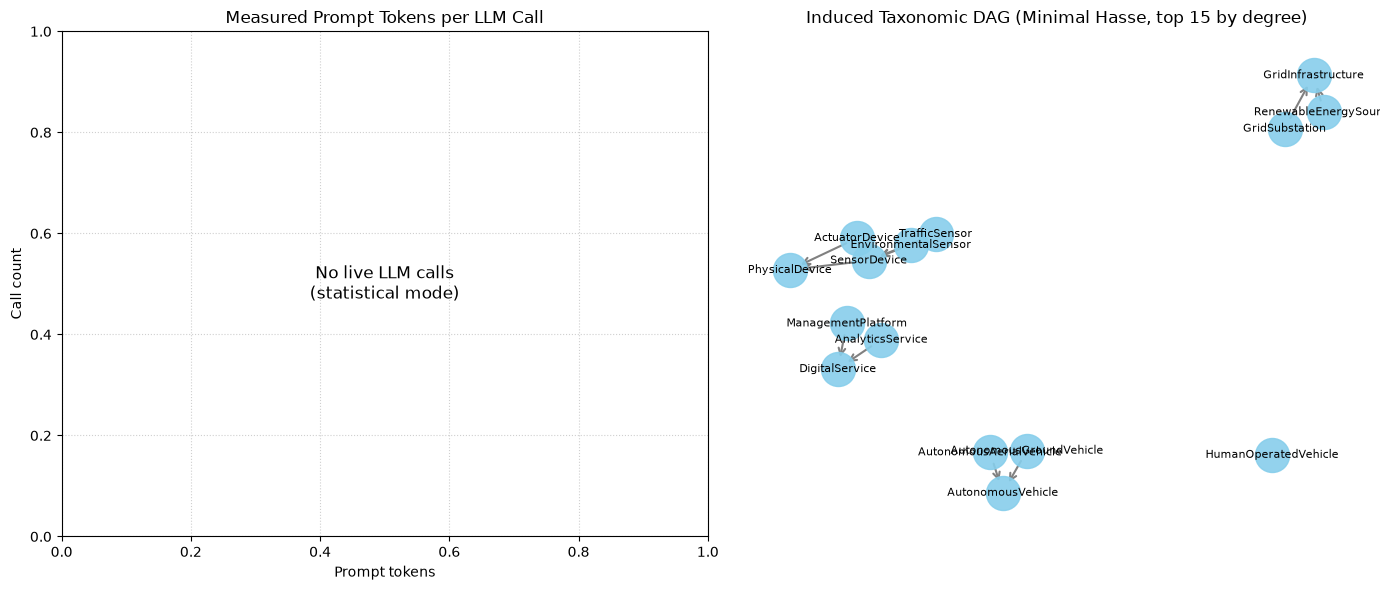

Diagnostic plot saved to /home/miskat/Projects/ABOX2TBOX/output/telemetry_diagnostics.png.
Pipeline completed successfully.


In [21]:
# Section 7.3: Visual Telemetry Dashboard & Taxonomic DAG Visualization
telemetry_plot_path: str = str(config["PLOT_PATH"])
os.makedirs(os.path.dirname(telemetry_plot_path) or ".", exist_ok=True)

fig, (ax_tokens, ax_dag) = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: measured prompt-token distribution
if live_prompt_tokens:
    ax_tokens.hist(live_prompt_tokens, bins=15, color="steelblue", edgecolor="black", alpha=0.7)
    ax_tokens.axvline(token_ceiling_bound, color="crimson", linestyle="--", linewidth=2,
                      label=f"Warn threshold ({token_ceiling_bound})")
    ax_tokens.legend()
else:
    ax_tokens.text(0.5, 0.5, "No live LLM calls\n(statistical mode)", ha="center", va="center", fontsize=12)
ax_tokens.set_title("Measured Prompt Tokens per LLM Call", fontsize=12)
ax_tokens.set_xlabel("Prompt tokens")
ax_tokens.set_ylabel("Call count")
ax_tokens.grid(True, linestyle=":", alpha=0.6)

# Subplot 2: the 15 best-connected classes of the Hasse diagram
connected_nodes: list[str] = sorted(
    (n for n in G_reduced.nodes() if G_reduced.degree(n) > 0),
    key=lambda n: (-G_reduced.degree(n), n),
)[:15]
if connected_nodes:
    sub_dag: nx.DiGraph = G_reduced.subgraph(connected_nodes)
    dag_layout: dict[str, Any] = nx.spring_layout(sub_dag, seed=seed_value)
    nx.draw_networkx_nodes(sub_dag, dag_layout, node_size=600, node_color="skyblue", alpha=0.9, ax=ax_dag)
    nx.draw_networkx_edges(sub_dag, dag_layout, arrowstyle="->", arrowsize=12, edge_color="gray", width=1.5, ax=ax_dag)
    nx.draw_networkx_labels(sub_dag, dag_layout, labels={n: local_name(n) for n in connected_nodes}, font_size=8, ax=ax_dag)
else:
    ax_dag.text(0.5, 0.5, "No subclass edges to display", ha="center", va="center", fontsize=12)
ax_dag.set_title("Induced Taxonomic DAG (Minimal Hasse, top 15 by degree)", fontsize=12)
ax_dag.axis("off")

fig.tight_layout()
fig.savefig(telemetry_plot_path, dpi=150)
plt.close(fig)
# plt.show()

print(f"Diagnostic plot saved to {telemetry_plot_path}.")
print("Pipeline completed successfully.")
